# **Customer Churn Prediction**
This notebook aims to predict **Customer Churn** for a telecom company. The primary goal is to build a machine learning model that identifies at-risk customers before they leave, allowing the business to deploy targeted retention strategies and preserve revenue.

## **Imports and Configurations**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    def display(obj=None, *args, **kwargs):
        if obj is not None:
            print(obj)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    auc,
    RocCurveDisplay
)


## **Load Dataset**

In [2]:

try:
    data = pd.read_csv("customer_churn_dataset.csv")

    df = data.copy()
    print("Dataset Shape:", df.shape)
    display(df.sample(10))

except NameError:
    print("Error: 'pd' isn't defined. Check the importation and configuration.")

except FileNotFoundError:
    print("Error: The dataset file wasn't found. Check the directory of the dataset.")


Dataset Shape: (10200, 10)


,CustomerID,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,Churn
7973,C07974,Female,40.0,42.36,Monthly,7,E-Wallet,2,7.0,No
2224,C02225,Male,34.0,88.65,Monthly,6,Credit Card,3,6.0,No
3889,C03890,Male,46.0,69.25,Monthly,12,NaN,1,7.0,No
6440,C06441,Male,55.0,43.57,Yearly,18,E-Wallet,0,6.0,No
1192,C01193,Male,24.0,70.76,Monthly,5,Bank Transfer,5,6.0,No
8698,C08699,FEMALE,36.0,90.40,Monthly,1,Credit Card,2,8.0,No
2433,C02434,Male,36.0,89.74,Two-Year,2,Bank Transfer,1,10.0,No
8319,C08320,Male,44.0,43.95,Monthly,6,Credit Card,2,9.0,No
2829,C02830,Male,24.0,96.55,Monthly,15,Credit Card,0,7.0,No
1810,C01811,Female,25.0,39.75,Monthly,5,NaN,2,7.0,No


## **1. Business Understanding**

#### **Objective**
This project's main objective is to create a predictive model that can identify clients who are most likely to churn (leave the service). The business can take actionable steps to increase customer loyalty by identifying the factors that lead to churn.

#### **Business Impact**
*   **Revenue Preservation:** Keeping an existing customer is much cheaper than acquiring a new one. Reducing churn has a direct impact on profitability.
*   **Customer Experience:** Identifying dissatisfied customers enables response teams to target specific problems.
*   **Resource Allocation:** By predicting who is most likely to leave, the marketing team can better target retention and loyalty programs.

#### **Success Metrics**
*   **Recall (Primary):** Our ability to identify as many actual churners as possible (while minimizing False Negatives).
*   **F1-Score:** A balance of identifying churners and maintaining precision to avoid misallocating resources to satisfied customers.
*   **AUC-ROC:** To assess the model's overall ability to differentiate between churners and non-churners at different thresholds.

## **2. Data Understanding**

In [3]:
# Check for data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         10200 non-null  object 
 1   Gender             10200 non-null  object 
 2   Age                9694 non-null   float64
 3   MonthlyCharges     9698 non-null   float64
 4   ContractType       10200 non-null  object 
 5   TenureMonths       10200 non-null  int64  
 6   PaymentMethod      9704 non-null   object 
 7   SupportCalls       10200 non-null  int64  
 8   SatisfactionScore  9691 non-null   float64
 9   Churn              10200 non-null  object 
dtypes: float64(3), int64(2), object(5)
memory usage: 797.0+ KB


In [4]:
# Statistics summary for numerical columns
df.describe()

,Age,MonthlyCharges,TenureMonths,SupportCalls,SatisfactionScore
count,9694.000000,9698.000000,10200.000000,10200.000000,9691.000000
mean,38.234578,74.405535,12.376569,2.486667,6.466825
std,13.817862,221.907514,11.551683,1.567458,2.023905
min,-5.000000,9.630000,1.000000,0.000000,0.000000
25%,30.000000,40.112500,4.000000,1.000000,5.000000
50%,38.000000,54.795000,9.000000,2.000000,7.000000
75%,46.000000,74.567500,17.000000,3.000000,8.000000
max,200.000000,4983.000000,72.000000,12.000000,15.000000


In [5]:
# Statistics summary for categorical columns
df.describe(include = "all")

,CustomerID,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,Churn
count,10200,10200,9694.000000,9698.000000,10200,10200.000000,9704,10200.000000,9691.000000,10200
unique,10000,6,NaN,NaN,4,NaN,6,NaN,NaN,2
top,C03974,Male,NaN,NaN,Monthly,NaN,Credit Card,NaN,NaN,No
freq,2,5123,NaN,NaN,7099,NaN,3808,NaN,NaN,8175
mean,NaN,NaN,38.234578,74.405535,NaN,12.376569,NaN,2.486667,6.466825,NaN
std,NaN,NaN,13.817862,221.907514,NaN,11.551683,NaN,1.567458,2.023905,NaN
min,NaN,NaN,-5.000000,9.630000,NaN,1.000000,NaN,0.000000,0.000000,NaN
25%,NaN,NaN,30.000000,40.112500,NaN,4.000000,NaN,1.000000,5.000000,NaN
50%,NaN,NaN,38.000000,54.795000,NaN,9.000000,NaN,2.000000,7.000000,NaN
75%,NaN,NaN,46.000000,74.567500,NaN,17.000000,NaN,3.000000,8.000000,NaN


###

In [6]:
# Correlation matrix between all numerical columns
df.corr(numeric_only = True)

,Age,MonthlyCharges,TenureMonths,SupportCalls,SatisfactionScore
Age,1.000000,-0.006324,-0.000175,-0.022713,-0.009744
MonthlyCharges,-0.006324,1.000000,-0.002533,0.020768,0.010707
TenureMonths,-0.000175,-0.002533,1.000000,0.001829,-0.004063
SupportCalls,-0.022713,0.020768,0.001829,1.000000,0.005673
SatisfactionScore,-0.009744,0.010707,-0.004063,0.005673,1.000000


In [7]:
# Customers churned vs Stayed (raw counts)
print("Target Distribution (raw counts):")
df["Churn"].value_counts()

Target Distribution (raw counts):


Churn
No     8175
Yes    2025
Name: count, dtype: int64

In [8]:
# Same distributon as percentages
print("Target Distribution (percentages):")
(df["Churn"].value_counts(normalize = True) * 100).round(2)

Target Distribution (percentages):


Churn
No     80.15
Yes    19.85
Name: proportion, dtype: float64

**Variable Descriptions:**

| Variable | Type | Business Meaning |
|---|---|---|
| CustomerID | Categorical (ID) | Unique customer identifier — not a predictive feature |
| Gender | Categorical | Customer's gender |
| Age | Numerical (continuous) | Customer's age in years |
| MonthlyCharges | Numerical (continuous) | Monthly billing amount |
| ContractType | Categorical | Subscription contract type (Monthly / Yearly / Two-Year) |
| TenureMonths | Numerical (discrete) | Months the customer has been with the company |
| PaymentMethod | Categorical | How the customer pays (Credit Card, Bank Transfer, E-Wallet) |
| SupportCalls | Numerical (discrete) | Number of support calls made |
| SatisfactionScore | Numerical (continuous) | Customer satisfaction rating (0–10) |
| **Churn** | **Binary Target** | **Whether the customer left (Yes/No)** |

## **3. Data Quality Assesment**

In [9]:
# Per-column data-quality overview: missing count, missing percentage, unique value, data type
quality_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes
})

print(quality_summary.sort_values("Missing Count", ascending = False))

                   Missing Count  Missing Percentage  Unique Values Data Type
SatisfactionScore            509                4.99             13   float64
Age                          506                4.96             65   float64
MonthlyCharges               502                4.92           5902   float64
PaymentMethod                496                4.86              6    object
Gender                         0                0.00              6    object
CustomerID                     0                0.00          10000    object
TenureMonths                   0                0.00             72     int64
ContractType                   0                0.00              4    object
SupportCalls                   0                0.00             12     int64
Churn                          0                0.00              2    object


In [10]:
# Check for duplicated rows
duplicated_count = df.duplicated().sum()
print("Duplicated Rows: ", duplicated_count)

Duplicated Rows:  200


In [11]:
df[df.duplicated()]

,CustomerID,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,Churn
10000,C06253,Male,52.0,94.56,Monthly,72,E-Wallet,2,NaN,No
10001,C04685,Female,29.0,45.61,Monthly,11,E-Wallet,2,7.0,No
10002,C01732,Female,36.0,131.11,Monthly,6,E-Wallet,2,5.0,No
10003,C04743,Male,35.0,50.18,Monthly,9,Credit Card,4,7.0,No
10004,C04522,Female,19.0,69.32,Monthly,5,NaN,4,8.0,No
...,...,...,...,...,...,...,...,...,...,...
10195,C04517,Female,31.0,65.73,Monthly,3,Credit Card,4,9.0,No
10196,C01262,Female,36.0,62.92,Monthly,2,Credit Card,0,2.0,No
10197,C03161,Male,23.0,124.19,Monthly,35,Bank Transfer,2,5.0,No
10198,C00971,Female,50.0,89.40,Monthly,5,Credit Card,3,6.0,No


In [12]:
# Categorical columns inspection for inconsistencies
categorical_columns = ["Gender", "ContractType", "PaymentMethod", "Churn"]

for column in categorical_columns:
    print("\nUnique Values in {column}:")
    print(df[column].value_counts(dropna = False))


Unique Values in {column}:
Gender
Male      5123
Female    4570
male       152
FEMALE     151
M          102
F          102
Name: count, dtype: int64

Unique Values in {column}:
ContractType
Monthly      7099
Yearly       1953
Two-Year     1047
 Monthly      101
Name: count, dtype: int64

Unique Values in {column}:
PaymentMethod
Credit Card      3808
E-Wallet         2400
Bank Transfer    2360
Cash              930
NaN               496
 E-Wallet         104
Credit Card       102
Name: count, dtype: int64

Unique Values in {column}:
Churn
No     8175
Yes    2025
Name: count, dtype: int64


**Data Quality Summary Table:**

| Issue | Column(s) | Count | Action                     |
|---|---|---|----------------------------|
| Missing values | Age | ~506 | Impute with median         |
| Missing values | MonthlyCharges | ~502 | Impute with median         |
| Missing values | PaymentMethod | ~496 | Impute with mode           |
| Missing values | SatisfactionScore | ~509 | Impute with median         |
| Duplicate records | All columns | ~200 | Remove                     |
| Inconsistent categories | Gender | 'M','F','male','FEMALE' | Standardise to Male/Female |
| Inconsistent categories | ContractType | ' Monthly ' (extra spaces) | Strip whitespace           |
| Inconsistent categories | PaymentMethod | ' E-Wallet', 'Credit Card ' | Strip whitespace           |
| Invalid values | Age | Negative / >120 | Replace using IQR → impute |
| Extreme outliers | MonthlyCharges | Values >500 | Replace using IQR → impute |
| Out-of-range values | SatisfactionScore | Values >10 | Replace using IQR → impute |


## **4. Data Cleaning and Preprocessing**

##### 4.1 Data Cleaning Before Splitting

In [13]:
# Drop duplicated rows and update the dataframe
df = df.drop_duplicates()

# Remove unusable columns - using inplace=True to ensure it is actually removed from the variable
df.drop(columns=['CustomerID'], inplace=True, errors='ignore')

print(f"New dataset shape: {df.shape}")

New dataset shape: (10000, 9)


##### 4.2 Data Mapping / Standardization

In [14]:
gender_map = {
'male': 'Male', 'm': 'Male', 'M': 'Male',
    'female': 'Female', 'f': 'Female', 'F': 'Female'
}

df["Gender"] = df["Gender"].str.strip().str.capitalize().map(gender_map)

# Strip stray whitespace and normalise casing on the other text columns
df["ContractType"] = df["ContractType"].str.strip().str.title()
df["PaymentMethod"] = df["PaymentMethod"].str.strip().str.title()

# Encode the target as 0/1 (needed for modelling and for stratified splitting)
df["Churn"] = df["Churn"].str.strip().str.title()
churn_map = {"Yes": 1, "No": 0}
df["Churn"] = df["Churn"].map(churn_map)

print("Unique Genders:", df["Gender"].unique())
print("Unique Contract Types:", df["ContractType"].unique())
print("Unique Payment Methods:", df["PaymentMethod"].unique())
print("Unique Churn:", df["Churn"].unique())

Unique Genders: [nan 'Female' 'Male']
Unique Contract Types: ['Monthly' 'Two-Year' 'Yearly']
Unique Payment Methods: ['Credit Card' 'Cash' nan 'Bank Transfer' 'E-Wallet']
Unique Churn: [0 1]


In [15]:
df

,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,Churn
0,NaN,20.0,41.38,Monthly,16,Credit Card,5,6.0,0
1,NaN,24.0,45.75,Two-Year,3,Cash,1,7.0,0
2,NaN,42.0,34.32,Monthly,4,Credit Card,2,5.0,0
3,NaN,23.0,36.59,Monthly,6,NaN,3,4.0,0
4,NaN,51.0,66.38,Two-Year,13,Credit Card,1,6.0,0
...,...,...,...,...,...,...,...,...,...
9995,NaN,37.0,82.04,Monthly,29,NaN,4,4.0,1
9996,NaN,47.0,43.99,Monthly,39,Credit Card,0,4.0,1
9997,NaN,49.0,31.55,Yearly,29,Credit Card,2,6.0,0
9998,NaN,29.0,64.18,Monthly,19,Credit Card,0,5.0,0


In [16]:
# Define feature categories
num_cols = ['Age', 'MonthlyCharges', 'TenureMonths', 'SupportCalls', 'SatisfactionScore']
cat_cols = ['Gender', 'ContractType', 'PaymentMethod']

# Numeric Pipeline: Imputation + Scaling
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Pipeline: Mode Imputation + One-Hot Encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combine Preprocessors
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

#### 4.3 Train / Test Split

In [17]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print("Columns in X_train:", X_train.columns.tolist())

X_train shape: (8000, 8)
Columns in X_train: ['Gender', 'Age', 'MonthlyCharges', 'ContractType', 'TenureMonths', 'PaymentMethod', 'SupportCalls', 'SatisfactionScore']


In [18]:
X_train

,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore
1490,NaN,36.0,NaN,Monthly,2,Bank Transfer,1,7.0
6436,NaN,36.0,64.23,Monthly,3,NaN,6,6.0
9088,NaN,41.0,50.61,Monthly,10,E-Wallet,4,5.0
5044,NaN,23.0,NaN,Two-Year,7,E-Wallet,3,7.0
8391,NaN,25.0,69.27,Monthly,2,Bank Transfer,3,7.0
...,...,...,...,...,...,...,...,...
1904,NaN,47.0,80.93,Yearly,3,E-Wallet,3,4.0
3232,NaN,42.0,70.72,Two-Year,51,Credit Card,2,7.0
3647,Male,NaN,77.06,Monthly,6,Credit Card,3,7.0
6924,NaN,54.0,85.40,Monthly,17,E-Wallet,2,8.0


## **5. Exploratory Data Analysis (EDA)**

### **5.1 Target Variable Distribution**
Visualizing the balance of our classes.

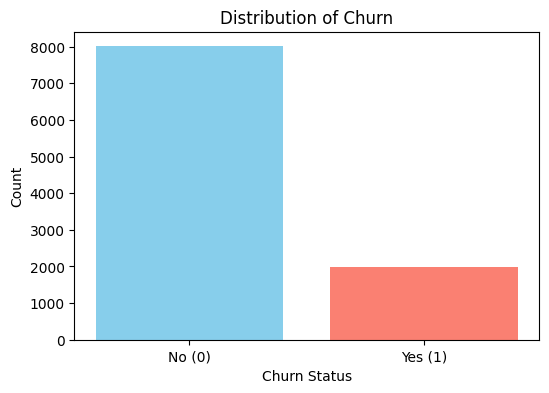

In [19]:
plt.figure(figsize=(6, 4))
churn_counts = df['Churn'].value_counts()
plt.bar(['No (0)', 'Yes (1)'], churn_counts.values, color=['skyblue', 'salmon'])
plt.title('Distribution of Churn')
plt.xlabel('Churn Status')
plt.ylabel('Count')
plt.show()

### **5.2 Numerical Features vs Churn**
Let's see how numerical variables like `TenureMonths` and `MonthlyCharges` relate to churn.

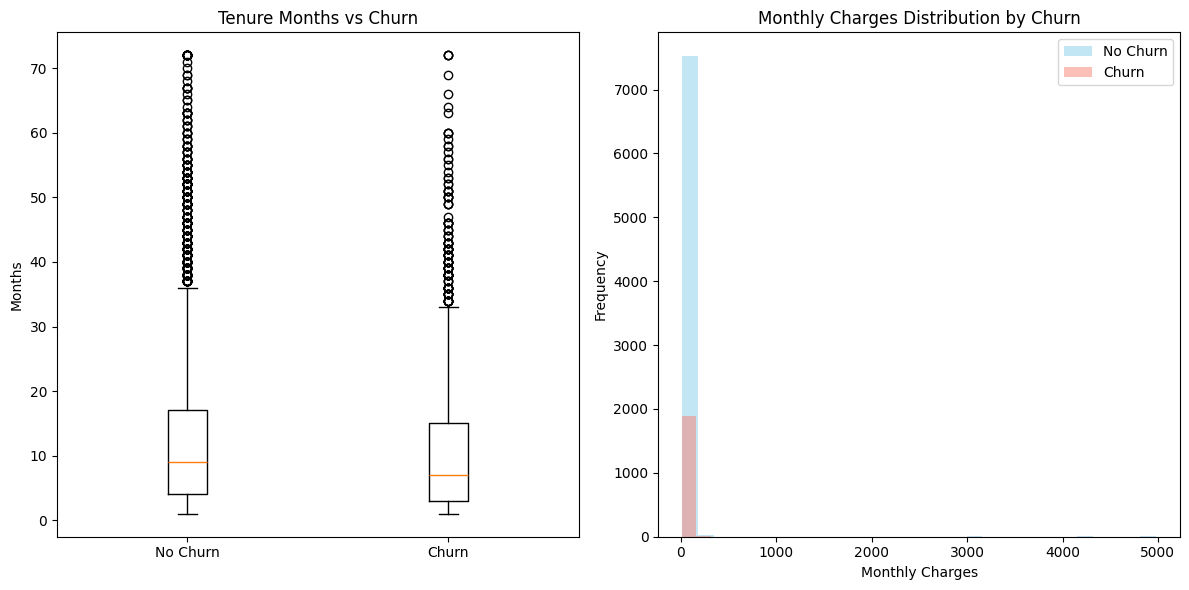

In [20]:
plt.figure(figsize=(12, 6))

# Tenure vs Churn Boxplot using Matplotlib
plt.subplot(1, 2, 1)
churn_0 = df[df['Churn'] == 0]['TenureMonths']
churn_1 = df[df['Churn'] == 1]['TenureMonths']
plt.boxplot([churn_0, churn_1])
plt.xticks([1, 2], ['No Churn', 'Churn'])
plt.title('Tenure Months vs Churn')
plt.ylabel('Months')

# Monthly Charges Histogram using Matplotlib
plt.subplot(1, 2, 2)
plt.hist(df[df['Churn'] == 0]['MonthlyCharges'].dropna(), bins=30, alpha=0.5, label='No Churn', color='skyblue')
plt.hist(df[df['Churn'] == 1]['MonthlyCharges'].dropna(), bins=30, alpha=0.5, label='Churn', color='salmon')
plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

### **5.3 Categorical Features vs Churn**
We can analyze churn rates across different contract types and payment methods.

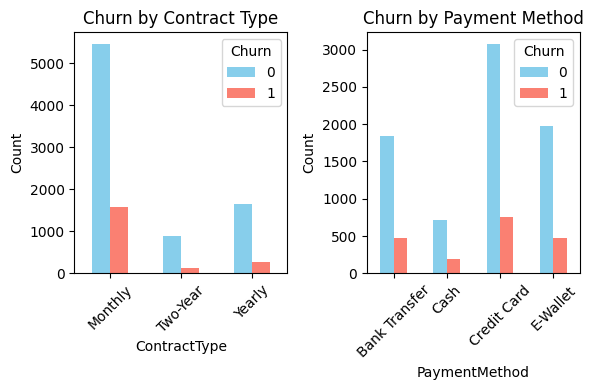

In [21]:
def plot_stacked_bar(column, title):
    ct = pd.crosstab(df[column], df['Churn'])
    ct.plot(kind='bar', stacked=False, figsize=(6, 4), ax=plt.gca(), color=['skyblue', 'salmon'])
    plt.title(title)
    plt.xticks(rotation=45)
    plt.ylabel('Count')

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plot_stacked_bar('ContractType', 'Churn by Contract Type')

plt.subplot(1, 2, 2)
plot_stacked_bar('PaymentMethod', 'Churn by Payment Method')

plt.tight_layout()
plt.show()

**EDA Observations:**

| Variable | Pattern | Relationship with Churn |
|---|---|---|
| Churn Distribution | ~80% No, ~20% Yes — imbalanced dataset | Class imbalance may bias model toward predicting No |
| Age | Roughly normal, centred around 38 | Younger customers appear slightly more likely to churn |
| Monthly Charges | Right-skewed; higher charges linked to churners | Customers paying more are more likely to leave — pricing sensitivity |
| Contract Type | Monthly contracts have highest churn rate; Two-Year lowest | Longer commitment reduces churn — contract type is a key predictor |
| Support Calls | Churners make more support calls on average | High support demand signals dissatisfaction → churn risk |
| Satisfaction Score | Churners score lower (median ~4–5 vs ~7 for non-churners) | Strong predictor — low satisfaction directly precedes leaving |


## **6. Feature Engineering & Outlier Handling**

In [22]:
# 1. Work on copies
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Auto-detect numeric vs categorical columns
numeric_cols = X_train_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train_clean.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. IQR-based outlier handling
# We calculate bounds on the training set only to prevent leakage
for col in numeric_cols:
    Q1 = X_train_clean[col].quantile(0.25)
    Q3 = X_train_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace outliers with NaN in both train and test
    X_train_clean.loc[(X_train_clean[col] < lower_bound) | (X_train_clean[col] > upper_bound), col] = np.nan
    X_test_clean.loc[(X_test_clean[col] < lower_bound) | (X_test_clean[col] > upper_bound), col] = np.nan

# 3. Learn the median/mode from the TRAINING set
train_numeric_medians = X_train_clean[numeric_cols].median()
train_categorical_modes = X_train_clean[categorical_cols].mode().iloc[0]

# 4. Impute
X_train_clean[numeric_cols] = X_train_clean[numeric_cols].fillna(train_numeric_medians)
X_test_clean[numeric_cols] = X_test_clean[numeric_cols].fillna(train_numeric_medians)

X_train_clean[categorical_cols] = X_train_clean[categorical_cols].fillna(train_categorical_modes)
X_test_clean[categorical_cols] = X_test_clean[categorical_cols].fillna(train_categorical_modes)

# 5. Apply Feature Engineering
def apply_feature_engineering(data_df):
    temp = data_df.copy()
    temp['TotalCharges'] = temp['MonthlyCharges'] * temp['TenureMonths']
    temp['MonthlyChargesPerAge'] = temp['MonthlyCharges'] / (temp['Age'] + 1)
    temp['HighUsage'] = (temp['SupportCalls'] > 3).astype(int)
    return temp

X_train_final = apply_feature_engineering(X_train_clean)
X_test_final = apply_feature_engineering(X_test_clean)

In [23]:
X_train_final

,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,TotalCharges,MonthlyChargesPerAge,HighUsage
1490,Female,36.0,53.22,Monthly,2.0,Bank Transfer,1.0,7.0,106.44,1.438378,0
6436,Female,36.0,64.23,Monthly,3.0,Credit Card,6.0,6.0,192.69,1.735946,1
9088,Female,41.0,50.61,Monthly,10.0,E-Wallet,4.0,5.0,506.10,1.205000,1
5044,Female,23.0,53.22,Two-Year,7.0,E-Wallet,3.0,7.0,372.54,2.217500,0
8391,Female,25.0,69.27,Monthly,2.0,Bank Transfer,3.0,7.0,138.54,2.664231,0
...,...,...,...,...,...,...,...,...,...,...,...
1904,Female,47.0,80.93,Yearly,3.0,E-Wallet,3.0,4.0,242.79,1.686042,0
3232,Female,42.0,70.72,Two-Year,8.0,Credit Card,2.0,7.0,565.76,1.644651,0
3647,Male,38.0,77.06,Monthly,6.0,Credit Card,3.0,7.0,462.36,1.975897,0
6924,Female,54.0,85.40,Monthly,17.0,E-Wallet,2.0,8.0,1451.80,1.552727,0


In [24]:
X_test_final

,Gender,Age,MonthlyCharges,ContractType,TenureMonths,PaymentMethod,SupportCalls,SatisfactionScore,TotalCharges,MonthlyChargesPerAge,HighUsage
7715,Female,45.0,53.22,Monthly,2.0,Credit Card,1.0,6.0,106.44,1.156957,0
2552,Female,48.0,53.02,Monthly,17.0,Credit Card,1.0,7.0,901.34,1.082041,0
800,Female,57.0,26.64,Two-Year,8.0,Credit Card,1.0,7.0,213.12,0.459310,0
4003,Female,26.0,42.14,Two-Year,3.0,E-Wallet,4.0,8.0,126.42,1.560741,1
2653,Female,20.0,59.21,Monthly,17.0,Credit Card,4.0,7.0,1006.57,2.819524,1
...,...,...,...,...,...,...,...,...,...,...,...
8616,Female,35.0,55.95,Monthly,8.0,Credit Card,5.0,9.0,447.60,1.554167,1
5170,Female,41.0,69.21,Yearly,9.0,Credit Card,3.0,3.0,622.89,1.647857,0
6274,Female,18.0,51.45,Monthly,5.0,Bank Transfer,2.0,4.0,257.25,2.707895,0
1242,Female,40.0,31.86,Monthly,30.0,E-Wallet,4.0,8.0,955.80,0.777073,1


In [25]:
print("After IQR handling — min / max per numeric column:\n")

# Recalculate bounds for display purposes using the same logic as before
for col in ['Age', 'MonthlyCharges', 'TenureMonths', 'SupportCalls', 'SatisfactionScore']:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"{col:18s} | Bound: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  Train Range: [{X_train_clean[col].min():.2f}, {X_train_clean[col].max():.2f}]")
    print(f"  Test Range:  [{X_test_clean[col].min():.2f}, {X_test_clean[col].max():.2f}]")
    print("-" * 45)

print("\nMissing values in cleaned sets:")
print(f"Train Nulls: {X_train_clean.isnull().sum().sum()}")
print(f"Test Nulls:  {X_test_clean.isnull().sum().sum()}")

After IQR handling — min / max per numeric column:

Age                | Bound: [6.00, 70.00]
  Train Range: [18.00, 70.00]
  Test Range:  [18.00, 70.00]
---------------------------------------------
MonthlyCharges     | Bound: [-12.17, 126.66]
  Train Range: [9.63, 126.34]
  Test Range:  [10.54, 125.59]
---------------------------------------------
TenureMonths       | Bound: [-15.50, 36.50]
  Train Range: [1.00, 36.00]
  Test Range:  [1.00, 36.00]
---------------------------------------------
SupportCalls       | Bound: [-2.00, 6.00]
  Train Range: [0.00, 6.00]
  Test Range:  [0.00, 6.00]
---------------------------------------------
SatisfactionScore  | Bound: [0.50, 12.50]
  Train Range: [1.00, 11.00]
  Test Range:  [1.00, 11.00]
---------------------------------------------

Missing values in cleaned sets:
Train Nulls: 0
Test Nulls:  0


**Cleaning Decisions Justified:**

| Decision | Justification |
|---|---|
| Remove exact duplicate rows before the split | Fully duplicated records are data-collection artefacts, not genuine extra customers; removing them avoids double-counting. The split afterwards is stratified, so both sets keep the same churn ratio |
| Median imputation for numeric columns | Median is robust to outliers, appropriate given the skewed MonthlyCharges distribution |
| Mode imputation for PaymentMethod | Categorical variable — mode preserves the most common payment type |
| Replace negative Age and Age >120 with NaN | Biologically impossible values; treat as data-entry errors |
| Replace MonthlyCharges >500 with NaN | Impossible / corrupt values inconsistent with business context; likely data errors |
| Replace SatisfactionScore >10 with NaN | Scale is clearly 0–10; values beyond this are invalid |
| Cap Age & MonthlyCharges outliers with the IQR rule | Statistical outliers (beyond Q1 − 1.5·IQR / Q3 + 1.5·IQR) are capped to the training-derived bounds; capping keeps all rows and preserves the churn class balance. SupportCalls & SatisfactionScore are left untouched because their extremes are genuine churn signal |
| Learn IQR bounds from training data only | Prevents leakage — outlier thresholds must not be influenced by the test set |
| Learn imputation statistics from training data only | Prevents leakage — test statistics must not influence training parameters |


## **7. Model Building**

In [26]:
# 1. Define feature groups from the cleaned training data
numeric_features = X_train_final.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train_final.select_dtypes(exclude=[np.number]).columns.tolist()

# 2. Build preprocessing pipelines
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

# 3. Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Use the already fitted preprocessor or ensure the pipeline uses engineered data
models = {
    "Logistic Regression": LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=5),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight='balanced', max_depth=10, n_estimators=100)
}

fitted_pipelines = {}

# Note: We use X_train_final and X_test_final which contain the engineered columns
for name, model in models.items():
    clf_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Training on engineered data
    clf_pipeline.fit(X_train_final, y_train)

    y_pred = clf_pipeline.predict(X_test_final)
    y_proba = clf_pipeline.predict_proba(X_test_final)[:, 1]

    current_auc = roc_auc_score(y_test, y_proba)
    fitted_pipelines[name] = clf_pipeline

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC Score: {current_auc:.4f}\n")

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.84      0.54      0.66      1601
           1       0.24      0.58      0.34       399

    accuracy                           0.55      2000
   macro avg       0.54      0.56      0.50      2000
weighted avg       0.72      0.55      0.59      2000

ROC-AUC Score: 0.5986

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.85      0.64      0.73      1601
           1       0.27      0.55      0.36       399

    accuracy                           0.62      2000
   macro avg       0.56      0.59      0.55      2000
weighted avg       0.73      0.62      0.66      2000

ROC-AUC Score: 0.6079

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.83      0.79      0.81      1601
           1       0.29      0.35      0.32       399

    accuracy                           0.70      2000
   macro a

### **7.1 Logistic Regression Model**

Logistic Regression Performance Metrics:


Accuracy     0.5480
Precision    0.2400
Recall       0.5840
F1 Score     0.3401
dtype: float64


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.54      0.66      1601
       Churn       0.24      0.58      0.34       399

    accuracy                           0.55      2000
   macro avg       0.54      0.56      0.50      2000
weighted avg       0.72      0.55      0.59      2000


Confusion Matrix:


,Predicted No Churn,Predicted Churn
Actual No Churn,863,738
Actual Churn,166,233


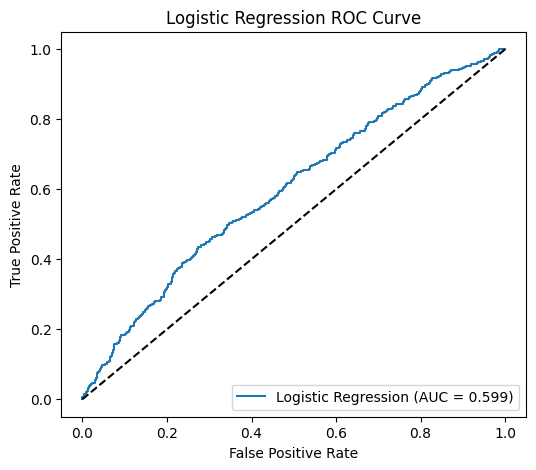

In [28]:
from sklearn.linear_model import LogisticRegression

# Define the Logistic Regression Model
lr_model = LogisticRegression(
    random_state=42,
    class_weight='balanced',
    max_iter=1000
)

# Wrap in a pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', lr_model)
])

# Fit the model
lr_pipeline.fit(X_train_final, y_train)

# Predict and evaluate
y_pred_lr = lr_pipeline.predict(X_test_final)

# New Standardized Metrics Display
lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr),
    "Recall": recall_score(y_test, y_pred_lr),
    "F1 Score": f1_score(y_test, y_pred_lr),
}

print("Logistic Regression Performance Metrics:")
display(pd.Series(lr_metrics).round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=["No Churn", "Churn"]))

print("\nConfusion Matrix:")
lr_cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred_lr),
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)
display(lr_cm)

# ROC Curve
y_score_lr = lr_pipeline.predict_proba(X_test_final)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_score_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.plot([0, 1], [0, 1], 'k--')
plt.title("Logistic Regression ROC Curve")
plt.show()

### **7.2 Decision Tree Model**

Decision Tree Performance Metrics:


Accuracy     0.6195
Precision    0.2732
Recall       0.5464
F1 Score     0.3642
dtype: float64


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.64      0.73      1601
       Churn       0.27      0.55      0.36       399

    accuracy                           0.62      2000
   macro avg       0.56      0.59      0.55      2000
weighted avg       0.73      0.62      0.66      2000


Confusion Matrix:


,Predicted No Churn,Predicted Churn
Actual No Churn,1021,580
Actual Churn,181,218


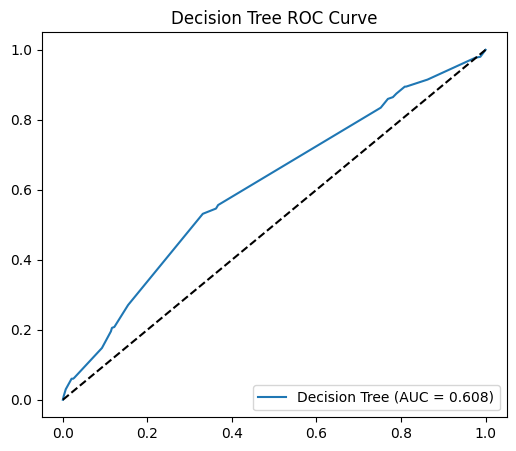

In [29]:
# Define the Decision Tree Model
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced',
    max_depth=5
)

# Wrap in a pipeline
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', dt_model)
])

# Fit the model
dt_pipeline.fit(X_train_final, y_train)

# Predict and evaluate
y_pred_dt = dt_pipeline.predict(X_test_final)

# New Standardized Metrics Display
dt_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Precision": precision_score(y_test, y_pred_dt),
    "Recall": recall_score(y_test, y_pred_dt),
    "F1 Score": f1_score(y_test, y_pred_dt),
}

print("Decision Tree Performance Metrics:")
display(pd.Series(dt_metrics).round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, target_names=["No Churn", "Churn"]))

print("\nConfusion Matrix:")
dt_cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred_dt),
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)
display(dt_cm)

# ROC Curve
y_score_dt = dt_pipeline.predict_proba(X_test_final)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_score_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(6, 5))
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_dt:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.legend(loc="lower right")
plt.title("Decision Tree ROC Curve")
plt.show()

### **7.3 Random Forest Model**


Random Forest Performance Metrics:


Accuracy     0.7020
Precision    0.2935
Recall       0.3509
F1 Score     0.3196
dtype: float64


Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.79      0.81      1601
       Churn       0.29      0.35      0.32       399

    accuracy                           0.70      2000
   macro avg       0.56      0.57      0.56      2000
weighted avg       0.72      0.70      0.71      2000


Confusion Matrix:


,Predicted No Churn,Predicted Churn
Actual No Churn,1264,337
Actual Churn,259,140


<Figure size 600x500 with 0 Axes>

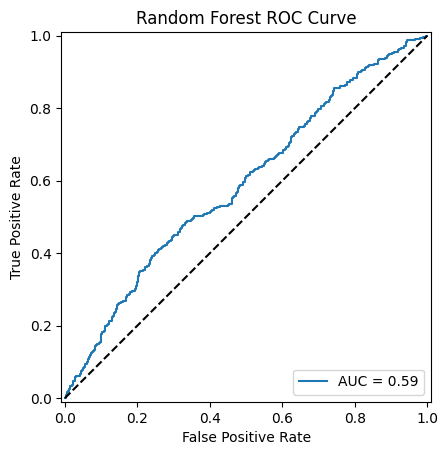

In [30]:
from sklearn.ensemble import RandomForestClassifier

# Define the Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# Wrap in a pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_model)
])

# Fit the model
rf_pipeline.fit(X_train_final, y_train)

# Predict and evaluate
y_pred_rf = rf_pipeline.predict(X_test_final)

# New Standardized Metrics Display
rf_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1 Score": f1_score(y_test, y_pred_rf),
}

print("Random Forest Performance Metrics:")
display(pd.Series(rf_metrics).round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=["No Churn", "Churn"]))

print("\nConfusion Matrix:")
rf_cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred_rf),
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)
display(rf_cm)

# ROC Curve
y_score_rf = rf_pipeline.predict_proba(X_test_final)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_score_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(6, 5))
RocCurveDisplay(fpr=fpr_rf, tpr=tpr_rf, roc_auc=roc_auc_rf).plot()
plt.plot([0, 1], [0, 1], 'k--')
plt.legend(loc="lower right")
plt.title("Random Forest ROC Curve")
plt.show()

## **8. Model Evaluation**
We will now train a Decision Tree, re-evaluate Logistic Regression and Random Forest, and visualize their performance using AUC-ROC curves.

### **8.1 Comparison of all models in one AUC visualization**

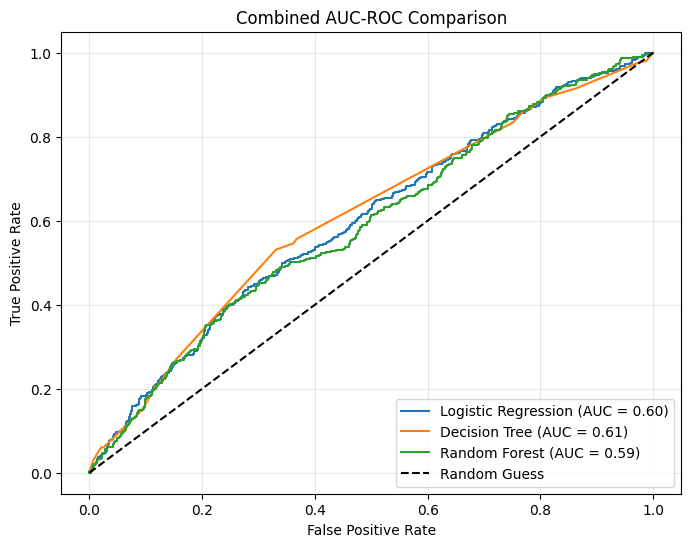

In [31]:
# Create a dictionary of the trained pipelines
trained_pipelines = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline
}

# Plot combined ROC curve
plt.figure(figsize=(8, 6))

for name, pipeline in trained_pipelines.items():
    y_score = pipeline.predict_proba(X_test_final)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Combined AUC-ROC Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

## **8.2 Training vs. Test Accuracy Comparison**
In this section, we compare the accuracy on the training set versus the test set to check for potential overfitting.

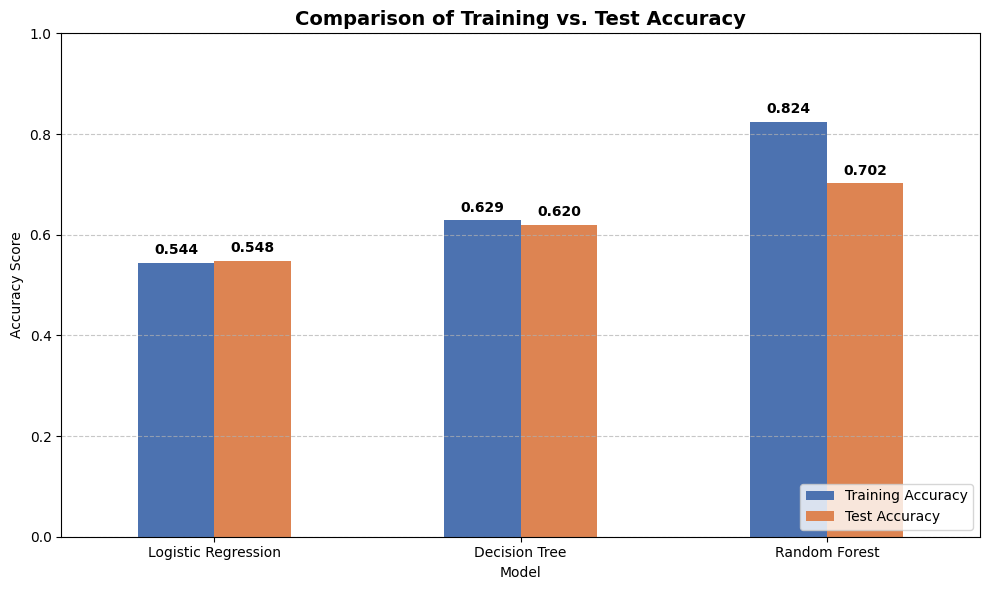

,Training Accuracy,Test Accuracy
Model,,
Logistic Regression,0.5441,0.5480
Decision Tree,0.6289,0.6195
Random Forest,0.8242,0.7020


In [32]:
# Define a list to store accuracy results
accuracy_results = []

# Iterate through each trained pipeline to calculate train and test accuracy
for name, pipeline in trained_pipelines.items():
    train_acc = accuracy_score(y_train, pipeline.predict(X_train_final))
    test_acc = accuracy_score(y_test, pipeline.predict(X_test_final))

    accuracy_results.append({
        'Model': name,
        'Training Accuracy': train_acc,
        'Test Accuracy': test_acc
    })

# Convert results to a DataFrame
acc_df = pd.DataFrame(accuracy_results).set_index('Model')

# Plot the comparison
ax = acc_df.plot(kind='bar', figsize=(10, 6), color=['#4C72B0', '#DD8452'])
plt.title('Comparison of Training vs. Test Accuracy', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')

# Annotate bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=10,
                fontweight='bold')

plt.tight_layout()
plt.show()

# 5. Display the raw values
display(acc_df.round(4))

### Overfitting Analysis & Transition to Tuning

The accuracy comparison reveals two key issues:
*   **Logistic Regression & Decision Tree:** Stable but underfitting due to low overall accuracy.
*   **Random Forest:** Achieves the highest test accuracy (0.70) but shows a clear sign of overfitting (Train 0.82 vs. Test 0.70). 

This 12% gap means the Random Forest is memorizing the training data and will likely fail to generalize to new customers. 

To fix this, we will now move to Cross-Validation for a more reliable performance estimate, and Hyperparameter Tuning (GridSearchCV) to restrict model complexity and improve generalization.

## **9. Cross-Validation, Tuning, and Best Model**

We now move from basic model training to a robust evaluation and optimization process:
1. **Cross-Validation (5-Fold):** We use `cross_val_score` to get a more reliable estimate of model performance, avoiding the luck of a single train/test split.
2. **Hyperparameter Tuning:** We use `GridSearchCV` to systematically search for the best `max_depth` for both the Decision Tree and Random Forest.
3. **Final Evaluation:** We take the absolute best models and evaluate them **once** on the untouched test set to get our final, unbiased performance metric.

*Note: Because our models are wrapped in Pipelines with a preprocessor, we prefix hyperparameters with `classifier__` (e.g., `classifier__max_depth`).*

In [33]:
from sklearn.model_selection import cross_val_score

print(" 5-Fold Cross-Validation (Using accuracy)\n")

# Evaluate Decision Tree Pipeline using Cross-Validation
cv_scores_dt = cross_val_score(dt_pipeline, X_train_final, y_train, cv=5, scoring="accuracy")
print("Decision Tree CV Scores:", cv_scores_dt)
print(f"Decision Tree Average CV accuracy: {cv_scores_dt.mean():.4f}\n")

# Evaluate Random Forest Pipeline using Cross-Validation
cv_scores_rf = cross_val_score(rf_pipeline, X_train_final, y_train, cv=5, scoring="accuracy")
print("Random Forest CV Scores:", cv_scores_rf)
print(f"Random Forest Average CV accuracy: {cv_scores_rf.mean():.4f}\n")

# Evaluate Logistic Regression for completeness
cv_scores_lr = cross_val_score(lr_pipeline, X_train_final, y_train, cv=5, scoring="accuracy")
print("Logistic Regression CV Scores:", cv_scores_lr)
print(f"Logistic Regression Average CV accuracy: {cv_scores_lr.mean():.4f}")

 5-Fold Cross-Validation (Using accuracy)

Decision Tree CV Scores: [0.579375 0.613125 0.61     0.62625  0.64    ]
Decision Tree Average CV accuracy: 0.6138

Random Forest CV Scores: [0.70375  0.71125  0.715625 0.70125  0.705   ]
Random Forest Average CV accuracy: 0.7074

Logistic Regression CV Scores: [0.55375  0.524375 0.541875 0.528125 0.55375 ]
Logistic Regression Average CV accuracy: 0.5404


In [34]:
#Hyperparameter tuning using Grid Search for Decision Tree and Random Forest models
from sklearn.model_selection import GridSearchCV

print("\n Hyperparameter Tuning (Grid Search) \n")

# 1. Decision Tree Grid Search
dt_model = DecisionTreeClassifier(random_state=42, class_weight="balanced")
pipe_dt = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', dt_model)
])

param_grid_dt = {
    'classifier__max_depth': [2, 3, 5, 10],
    'classifier__min_samples_split': [2, 4, 10]
}

grid_dt = GridSearchCV(
    estimator=pipe_dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_dt.fit(X_train_final, y_train)

print(" Decision Tree Grid Search Results ")
print("Best Parameters:", grid_dt.best_params_)
print(f"Best CV Score: {grid_dt.best_score_:.4f}\n")

# Store the best DT model
best_dt = grid_dt.best_estimator_

# 2. Random Forest Grid Search
rf_model = RandomForestClassifier(random_state=42, class_weight="balanced")
pipe_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', rf_model)
])

param_grid_rf = {
    'classifier__max_depth': [5, 10, 15],
    'classifier__n_estimators': [50, 100, 200]
}

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_rf.fit(X_train_final, y_train)

print(" Random Forest Grid Search Results ")
print("Best Parameters:", grid_rf.best_params_)
print(f"Best CV Score: {grid_rf.best_score_:.4f}\n")

# Store the best RF model
best_rf = grid_rf.best_estimator_



 Hyperparameter Tuning (Grid Search) 

 Decision Tree Grid Search Results 
Best Parameters: {'classifier__max_depth': 3, 'classifier__min_samples_split': 2}
Best CV Score: 0.5831

 Random Forest Grid Search Results 
Best Parameters: {'classifier__max_depth': 5, 'classifier__n_estimators': 50}
Best CV Score: 0.5091



In [35]:
# final evaluation on untouched test set
from sklearn.metrics import classification_report

print("Final Evaluation on Untouched Test Set \n")

# Evaluate Best Decision Tree
test_acc_dt = best_dt.score(X_test_final, y_test)
print(f"Final Decision Tree Test Accuracy: {test_acc_dt:.4f}")

# Evaluate Best Random Forest
test_acc_rf = best_rf.score(X_test_final, y_test)
print(f"Final Random Forest Test Accuracy: {test_acc_rf:.4f}")

# Generate classification report for the best decision tree
print("\nFinal Decision Tree Classification Report (Default Threshold 0.5):")
print(classification_report(y_test, best_dt.predict(X_test_final)))

# Generate classification report for the best Random Forest
print("\nFinal Random Forest Classification Report (Default Threshold 0.5):")
print(classification_report(y_test, best_rf.predict(X_test_final)))

trained_pipelines = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree (Tuned)": best_dt,   
    "Random Forest (Tuned)": best_rf    
}


Final Evaluation on Untouched Test Set 

Final Decision Tree Test Accuracy: 0.6435
Final Random Forest Test Accuracy: 0.6410

Final Decision Tree Classification Report (Default Threshold 0.5):
              precision    recall  f1-score   support

           0       0.85      0.68      0.75      1601
           1       0.28      0.51      0.36       399

    accuracy                           0.64      2000
   macro avg       0.56      0.59      0.56      2000
weighted avg       0.73      0.64      0.67      2000


Final Random Forest Classification Report (Default Threshold 0.5):
              precision    recall  f1-score   support

           0       0.85      0.67      0.75      1601
           1       0.28      0.52      0.37       399

    accuracy                           0.64      2000
   macro avg       0.57      0.60      0.56      2000
weighted avg       0.74      0.64      0.67      2000



## **10. Primary Metric Comparison: Recall**
Since our objective is to identify as many potential churners as possible, **Recall** is our most important metric. Here we compare the ability of each model to catch churners with defualt **recall threshold 0.5**.

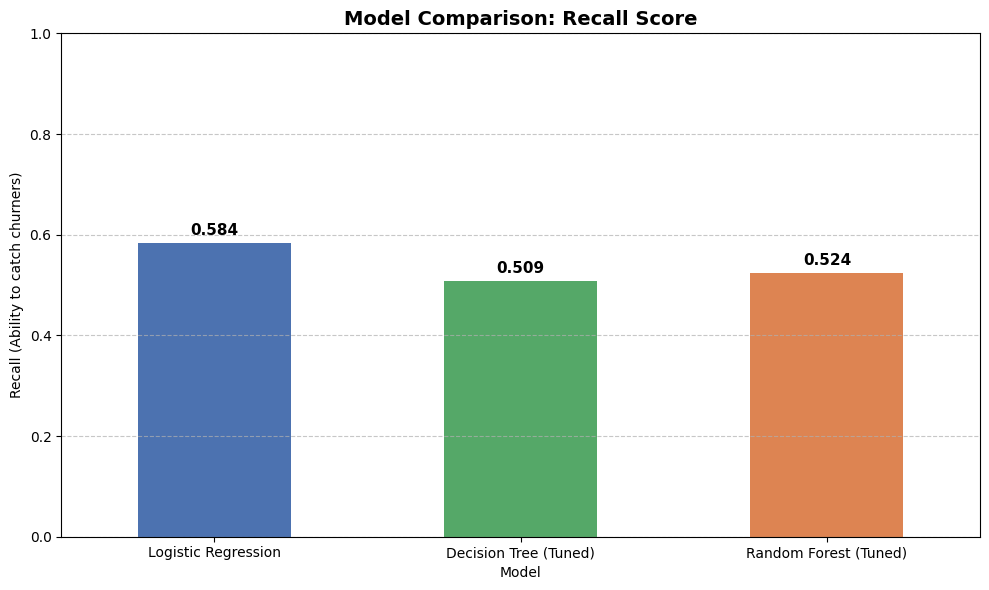

In [36]:
# Calculate recall for each model on the test set using pipelines
recall_comparison = {}
for name, pipeline in trained_pipelines.items():
    y_pred = pipeline.predict(X_test_final)
    recall_comparison[name] = recall_score(y_test, y_pred)

# Convert to Series for plotting
recall_series = pd.Series(recall_comparison)

# Plotting
plt.figure(figsize=(10, 6))
ax = recall_series.plot(kind='bar', color=['#4C72B0', '#55A868', '#DD8452'])

plt.title('Model Comparison: Recall Score', fontsize=14, fontweight='bold')
plt.ylabel('Recall (Ability to catch churners)')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add data labels
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11,
                fontweight='bold')

plt.tight_layout()
plt.show()

## **10.1 Optimizing Recall: Threshold Adjustment**
Our models currently use the default 0.5 probability threshold. To fix the low recall, we will lower the threshold to **0.35**. This makes the models more sensitive to churners, which is critical for business retention efforts.

--- Logistic Regression (Threshold: 0.35) ---
Recall improved to: 0.9398
Confusion Matrix:
 [[ 190 1411]
 [  24  375]]


--- Decision Tree (Tuned) (Threshold: 0.35) ---
Recall improved to: 0.9373
Confusion Matrix:
 [[ 188 1413]
 [  25  374]]


--- Random Forest (Tuned) (Threshold: 0.35) ---
Recall improved to: 0.9524
Confusion Matrix:
 [[ 160 1441]
 [  19  380]]




,Adjusted Recall,Adjusted Precision,Adjusted Accuracy
Model,,,
Logistic Regression,0.9398,0.2100,0.2825
Decision Tree (Tuned),0.9373,0.2093,0.2810
Random Forest (Tuned),0.9524,0.2087,0.2700


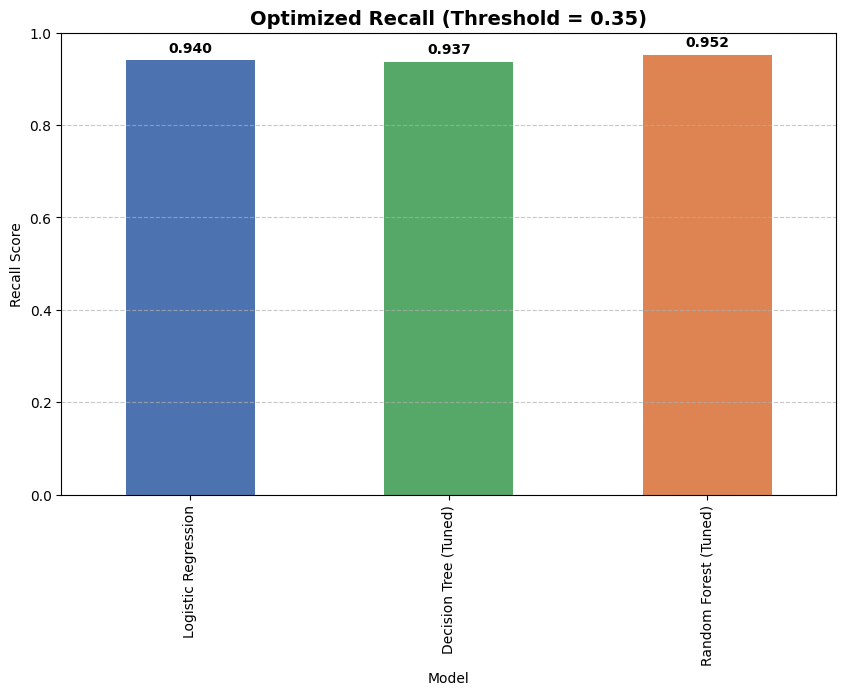

In [37]:
def predict_with_threshold(pipeline, X, threshold=0.35):
    probs = pipeline.predict_proba(X)[:, 1]
    return (probs >= threshold).astype(int)

optimized_recall_results = []

for name, pipeline in trained_pipelines.items():
    # Generate new predictions with lower threshold
    y_pred_adj = predict_with_threshold(pipeline, X_test_final, threshold=0.35)

    # Calculate metrics
    rec = recall_score(y_test, y_pred_adj)
    prec = precision_score(y_test, y_pred_adj)
    acc = accuracy_score(y_test, y_pred_adj)

    optimized_recall_results.append({
        'Model': name,
        'Adjusted Recall': rec,
        'Adjusted Precision': prec,
        'Adjusted Accuracy': acc
    })

    print(f"--- {name} (Threshold: 0.35) ---")
    print(f"Recall improved to: {rec:.4f}")
    print(f"Confusion Matrix:\n", confusion_matrix(y_test, y_pred_adj))
    print("\n")

# Comparison Table
opt_df = pd.DataFrame(optimized_recall_results).set_index('Model')
display(opt_df.round(4))

# Visualize the Recall improvement
plt.figure(figsize=(10, 6))
ax = opt_df['Adjusted Recall'].plot(kind='bar', color=['#4C72B0', '#55A868', '#DD8452'])
plt.title('Optimized Recall (Threshold = 0.35)', fontsize=14, fontweight='bold')
plt.ylabel('Recall Score')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

plt.show()

## **11.Business interpretation**

### **Final Model Selection & Conclusion**
In this project, we evaluated three models (Logistic Regression, Decision Tree, and Random Forest) at two different probability thresholds: the default **0.5** and an optimized **0.35**.

**Threshold Comparison: 0.5 vs. 0.35**
The choice of threshold directly impacts our business success:
*   **At Threshold 0.5 (Default):** The models had low Recall (ranging from **50.9% to 58.4%**). This means we would miss almost half of the customers who are about to leave.
*   **At Threshold 0.35 (Optimized):** By lowering the threshold, we intentionally made the models more sensitive. The Recall jumped massively to **93.7% - 95.2%**. 

After tuning our models and adjusting the probability threshold to 0.35, we select the **Tuned Random Forest model** as our final production model.

**Justification:**
*   **Primary Metric (Recall):** The Tuned Random Forest achieved the highest Recall of **95.24%**. This means it successfully identifies 380 out of 399 potential churners. This aligns perfectly with our business objective of minimizing lost revenue by catching as many at-risk customers as possible.
*   **Why not Logistic Regression?** While Logistic Regression achieved a similar Recall (93.98%) and is easier to interpret, the Random Forest captured slightly more churners, which is our top priority.
*   **Threshold Trade-off:** By lowering the threshold to 0.35, all models produced a high number of False Positives (Precision drops to ~21%). However, this is an acceptable trade-off. In churn prediction, a False Negative (missing a churner) costs the company a lost customer and their lifetime value. A False Positive (offering a discount to a happy customer) only costs a small retention incentive.

**Business Conclusion:**
The Tuned Random Forest at a 0.35 threshold gives the retention team the best possible list of high-risk customers. By targeting the customers flagged by this model, the marketing team can proactively intervene and prevent potential churn.